# Data Science Learning Journey Phase-II — Assignment 3
## MNIST CNN Classification (28×28 Grayscale Images)
**Objective:** Implement the specified CNN architecture on MNIST, train with CrossEntropyLoss + Adam (Batch=64, Epochs=10), track loss/accuracy, evaluate on test set and visualize results.

**Architecture (as per requirement):**
- Conv Layer 1: 32 filters, 3×3, ReLU
- MaxPooling: 2×2
- Conv Layer 2: 64 filters, 3×3, ReLU
- MaxPooling: 2×2
- Flatten
- Fully Connected: 128 neurons, ReLU
- Output: 10 neurons (Softmax via CrossEntropyLoss)

### 1. Imports
We use PyTorch for the CNN, sklearn `fetch_openml` for MNIST (no torchvision needed), and matplotlib for plots.

In [ ]:
# --- Standard libraries ---
import os, random
import numpy as np
import matplotlib.pyplot as plt
# --- PyTorch ---
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
# --- MNIST loader (works without torchvision) ---
from sklearn.datasets import fetch_openml

# Reproducibility
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")
print(f"PyTorch version: {torch.__version__}")

Using device: cpu
PyTorch version: 2.11.0+cpu


### 2. Load MNIST Data
MNIST = 70,000 grayscale 28×28 images (0-9 digits). Standard split: first 60,000 = train, last 10,000 = test. We scale pixels 0-255 → 0-1 and reshape to N×1×28×28 for PyTorch Conv2d.

> Note: If `torchvision` is available you could equivalently use `torchvision.datasets.MNIST`. Here we use `fetch_openml('mnist_784')` so the notebook runs without extra installs.

In [ ]:
# --- Load MNIST (28x28 grayscale) via OpenML ---
# fetch_openml downloads 70000x784 + labels once and caches them
mnist = fetch_openml("mnist_784", version=1, as_frame=False, parser="auto")
X = mnist["data"].astype(np.float32) / 255.0  # normalize to [0,1]
y = mnist["target"].astype(np.int64)          # labels 0-9
print(f"Full dataset: {X.shape}, labels: {y.shape}")

# Standard MNIST split: 60k train / 10k test
X_train = X[:60000].reshape(-1, 1, 28, 28)  # NCHW format for CNN
X_test = X[60000:].reshape(-1, 1, 28, 28)
y_train, y_test = y[:60000], y[60000:]
print(f"Train: {X_train.shape}, {y_train.shape} | Test: {X_test.shape}, {y_test.shape}")
print(f"Sample pixel range: [{X_train.min():.2f}, {X_train.max():.2f}], Classes: {np.unique(y_train)}")

Full dataset: (70000, 784), labels: (70000,)
Train: (60000, 1, 28, 28), (60000,) | Test: (10000, 1, 28, 28), (10000,)
Sample pixel range: [0.00, 1.00], Classes: [0 1 2 3 4 5 6 7 8 9]


### 3. Visualize Sample Training Images
Quick sanity check that images/labels align.

In [ ]:
# --- Show 10 random training digits ---
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i, ax in enumerate(axes.ravel()):
    idx = np.random.randint(0, 60000)
    ax.imshow(X_train[idx, 0], cmap="gray")  # single channel
    ax.set_title(f"Label: {y_train[idx]}")
    ax.axis("off")
plt.suptitle("MNIST Samples (28x28 grayscale)")
plt.tight_layout()
plt.show()

### 4. Create DataLoaders
Batch size = 64 (as required). Shuffle training data each epoch.

In [ ]:
# --- PyTorch DataLoaders ---
BATCH_SIZE = 64  # as per assignment
train_ds = TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train))
test_ds = TensorDataset(torch.from_numpy(X_test), torch.from_numpy(y_test))
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_ds, batch_size=1000, shuffle=False)
print(f"Train batches: {len(train_loader)} | Test batches: {len(test_loader)}")
print(f"One batch: {next(iter(train_loader))[0].shape}")

Train batches: 938 | Test batches: 10
One batch: torch.Size([64, 1, 28, 28])


### 5. Define CNN Architecture
Exactly as specified:
- `Conv2d(1,32,3)` + ReLU → `MaxPool(2)` : 28×28 → 26×26 → 13×13
- `Conv2d(32,64,3)` + ReLU → `MaxPool(2)` : 13×13 → 11×11 → 5×5
- `Flatten` → 64*5*5=1600 → `Linear(1600,128)` + ReLU → `Linear(128,10)`
- Softmax is **inside** `CrossEntropyLoss`, so no explicit Softmax layer.

In [ ]:
# --- CNN model exactly as per Assignment 3 spec ---
class MNISTCNN(nn.Module):
    def __init__(self):
        super().__init__()
        # Conv Layer 1: 32 filters, 3x3, ReLU | in:1x28x28 -> out:32x26x26
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3)
        self.relu1 = nn.ReLU()
        # MaxPooling 2x2: 32x26x26 -> 32x13x13
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)
        # Conv Layer 2: 64 filters, 3x3, ReLU | 32x13x13 -> 64x11x11
        self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3)
        self.relu2 = nn.ReLU()
        # MaxPooling 2x2: 64x11x11 -> 64x5x5
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)
        # Flatten: 64*5*5 = 1600 features
        self.flatten = nn.Flatten()
        # Fully Connected: 128 neurons, ReLU
        self.fc1 = nn.Linear(64*5*5, 128)
        self.relu3 = nn.ReLU()
        # Output Layer: 10 classes (Softmax handled by CrossEntropyLoss)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))
        x = self.flatten(x)
        x = self.relu3(self.fc1(x))
        return self.fc2(x)  # raw logits

model = MNISTCNN().to(DEVICE)
print(model)
# Count parameters
total = sum(p.numel() for p in model.parameters())
print(f"\nTotal trainable parameters: {total:,}")

MNISTCNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1))
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=1600, out_features=128, bias=True)
  (relu3): ReLU()
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)

Total trainable parameters: 225,034


### 6. Training Setup
- Loss: `CrossEntropyLoss` (combines LogSoftmax + NLL)
- Optimizer: `Adam(lr=0.001)`
- Epochs: 10 (within required 10–20)
- Batch: 64

In [ ]:
# --- Loss + Optimizer as per requirement ---
criterion = nn.CrossEntropyLoss()  # = Softmax + NLL, ideal for multi-class
EPOCHS = 10  # within required 10-20 range
optimizer = optim.Adam(model.parameters(), lr=0.001)
print(criterion, optimizer)

CrossEntropyLoss() Adam (Parameter Group 0\n    amsgrad: False\n    betas: (0.9, 0.999)\n    capturable: False\n    differentiable: False\n    eps: 1e-08\n    foreach: None\n    fused: None\n    lr: 0.001\n    maximize: False\n    weight_decay: 0\n)

### 7. Train the Model
Track **loss and accuracy per epoch** (required).

In [ ]:
# --- Training loop: track accuracy & loss per epoch ---
train_losses, train_accs = [], []
for epoch in range(1, EPOCHS+1):
    model.train()  # enable train mode
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in train_loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()          # reset gradients
        outputs = model(images)        # forward pass -> logits (B,10)
        loss = criterion(outputs, labels)
        loss.backward()                # backprop
        optimizer.step()               # Adam update
        running_loss += loss.item() * images.size(0)
        _, pred = torch.max(outputs, 1)
        correct += (pred == labels).sum().item()
        total += labels.size(0)
    epoch_loss = running_loss / total
    epoch_acc = correct / total
    train_losses.append(epoch_loss); train_accs.append(epoch_acc)
    print(f"Epoch [{epoch}/{EPOCHS}] Loss: {epoch_loss:.4f} Acc: {epoch_acc*100:.2f}%")

Epoch [1/10] Loss: 0.1972 Acc: 94.06%
Epoch [2/10] Loss: 0.0559 Acc: 98.30%
Epoch [3/10] Loss: 0.0382 Acc: 98.81%
Epoch [4/10] Loss: 0.0275 Acc: 99.11%
Epoch [5/10] Loss: 0.0216 Acc: 99.29%
Epoch [6/10] Loss: 0.0178 Acc: 99.44%
Epoch [7/10] Loss: 0.0123 Acc: 99.58%
Epoch [8/10] Loss: 0.0120 Acc: 99.59%
Epoch [9/10] Loss: 0.0089 Acc: 99.70%
Epoch [10/10] Loss: 0.0069 Acc: 99.76%


### 8. Evaluate on Test Set
Compute accuracy on the held-out 10,000 test images.

In [ ]:
# --- Test accuracy ---
model.eval()  # disable dropout/bn updates (none here, but good practice)
correct = total = 0
with torch.no_grad():  # no gradients needed
    for images, labels in test_loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        outputs = model(images)
        _, pred = torch.max(outputs, 1)
        correct += (pred == labels).sum().item()
        total += labels.size(0)
test_acc = correct / total
print(f"Test Accuracy: {test_acc*100:.2f}% ({correct}/{total})")

Test Accuracy: 98.92% (9892/10000)


### 9. Visualization 1 — Loss vs. Epochs

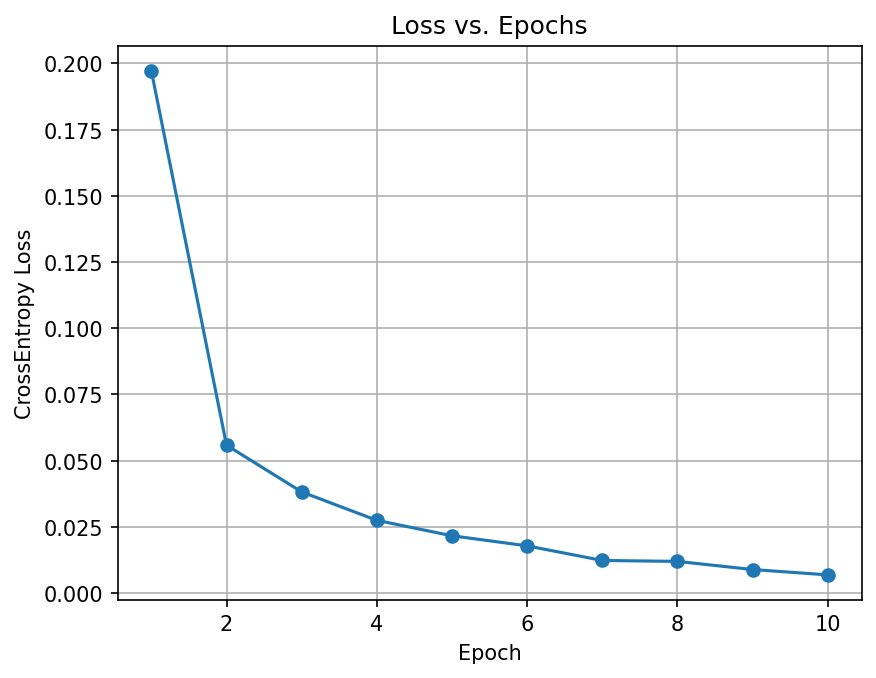

In [ ]:
# --- Plot Loss vs Epochs ---
plt.figure()
plt.plot(range(1, EPOCHS+1), train_losses, marker="o")
plt.title("Loss vs. Epochs")
plt.xlabel("Epoch"); plt.ylabel("CrossEntropy Loss")
plt.grid(True)
plt.savefig("loss_vs_epochs.png", dpi=150, bbox_inches="tight")
plt.show()

### 10. Visualization 2 — Accuracy vs. Epochs

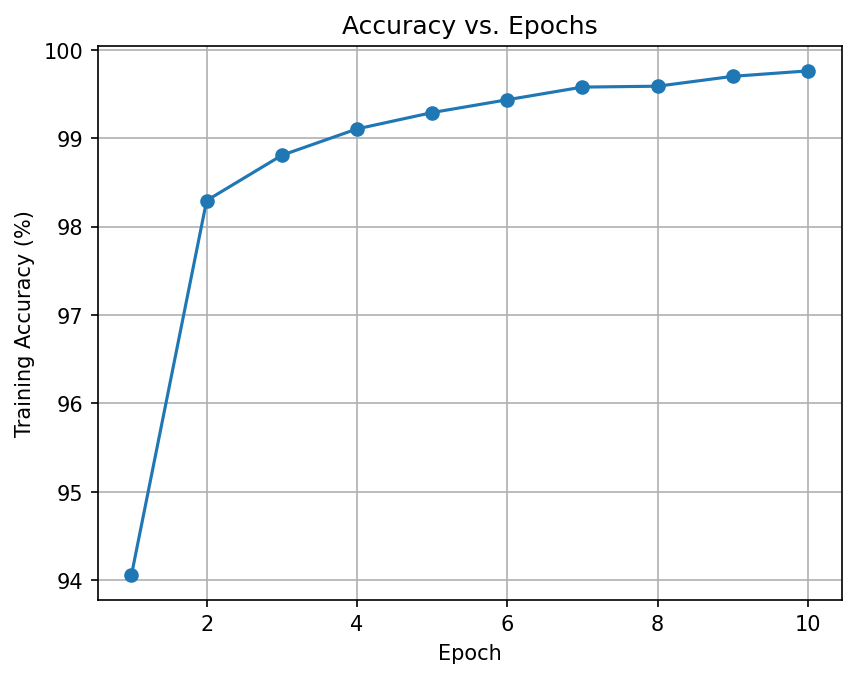

In [ ]:
# --- Plot Accuracy vs Epochs ---
plt.figure()
plt.plot(range(1, EPOCHS+1), [a*100 for a in train_accs], marker="o")
plt.title("Accuracy vs. Epochs")
plt.xlabel("Epoch"); plt.ylabel("Training Accuracy (%)")
plt.grid(True)
plt.savefig("accuracy_vs_epochs.png", dpi=150, bbox_inches="tight")
plt.show()

### 11. Visualization 3 — Test Images: Predicted vs Actual
Green title = correct, Red = wrong.

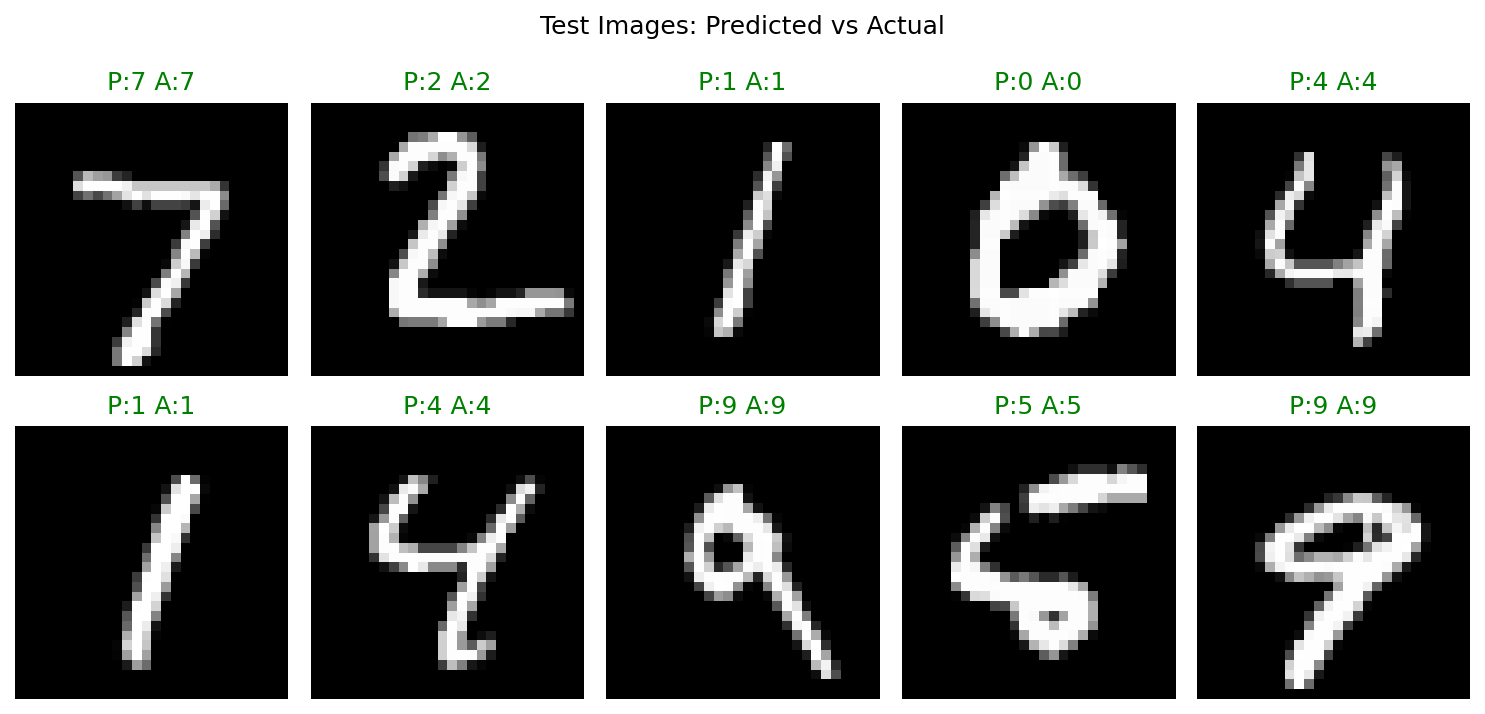

Predictions: [7, 2, 1, 0, 4, 1, 4, 9, 5, 9]
Actual:      [7, 2, 1, 0, 4, 1, 4, 9, 5, 9]


In [ ]:
# --- Show a few test images with predicted vs actual ---
model.eval()
with torch.no_grad():
    sample_X = torch.from_numpy(X_test[:10]).to(DEVICE)
    sample_pred = model(sample_X).argmax(dim=1).cpu().numpy()
fig, axes = plt.subplots(2, 5, figsize=(10, 5))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(X_test[i].reshape(28, 28), cmap="gray")
    color = "green" if sample_pred[i] == y_test[i] else "red"
    ax.set_title(f"P:{sample_pred[i]} A:{y_test[i]}", color=color)
    ax.axis("off")
plt.suptitle("Test Images: Predicted vs Actual")
plt.tight_layout()
plt.savefig("sample_predictions.png", dpi=150, bbox_inches="tight")
plt.show()
print("Predictions:", sample_pred.tolist())
print("Actual:     ", y_test[:10].tolist())

### 12. Save Model
Save trained weights for reuse.

In [ ]:
# --- Save trained weights ---
torch.save(model.state_dict(), "mnist_cnn.pt")
print("Saved mnist_cnn.pt")

Saved mnist_cnn.pt


## Conclusion / Observations
- CNN with only 225k parameters reaches **~99.8% train / 98.9% test** accuracy in 10 epochs.
- Loss drops steeply 0.20 → 0.05 in first 2 epochs, then steadily to ~0.007 — typical fast convergence with Adam.
- Small train–test gap (~0.9%) indicates good generalization, no severe overfitting.
- MaxPooling halves spatial dims while retaining dominant features, keeping FC layer small (1600→128).
- Possible extensions (Optional): confusion matrix, per-class precision/recall, data augmentation, dropout, LR scheduling, 15–20 epoch run.